# E03 — Productos estructurados: diseño y pricing con volatilidad local

**Objetivos:** descomponer reverse convertibles, barrier reverse convertibles, notas de capital protegido y
autocallables Phoenix y Athena en bono más opciones; valorarlos por Monte Carlo con la volatilidad local de D3 y
comparar con volatilidad plana; incluir la financiación del emisor y su margen; diseñar un Phoenix a cinco años
que pague un 6 % dejando un 2 % al emisor.

**Fuentes:** Schofield, *Equity Derivatives*, cap. 12 (12.2 a 12.4 y 12.7); Hull cap. 26; Gatheral (2006) para la
volatilidad local. Datos sintéticos: el índice, la curva €STR y la superficie SSVI de la Parte D.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

import time
from derivlab.market import sample_market
from derivlab.curves import build_curves, discount_t
from derivlab.equity import EquityMarket, SSVI
from derivlab.structured import (index_perf_lv, index_perf_flat, perf_from_x, funding_dfs, autocall_cashflows,
                                 note_value, solve_coupon, expected_life, reverse_convertible, capital_protected)

estr, eur = build_curves(sample_market())
mkt = EquityMarket(estr)
surface = SSVI()
SPREAD = 0.008                     # issuer funding spread over €STR
MARGIN = 0.02                      # the issuer keeps 2% of the issue price
TARGET = 1.0 - MARGIN

t0 = time.time()
q_obs = np.arange(1, 21) * 0.25                         # quarterly observations over five years
perf_lv, x_lv = index_perf_lv(mkt, surface, q_obs, n_paths=60000, steps_per_year=250, seed=11)
d_obs = np.arange(1, 253) / 252                         # daily closes over one year
perf_d_lv, _ = index_perf_lv(mkt, surface, d_obs, n_paths=40000, steps_per_year=252, seed=12)
atm5, atm1 = float(surface.vol(0.0, 5.0)), float(surface.vol(0.0, 1.0))
perf_flat, _ = index_perf_flat(mkt, atm5, q_obs, n_paths=60000, seed=11)
perf_d_flat, _ = index_perf_flat(mkt, atm1, d_obs, n_paths=40000, seed=12)
print(f"Simulated local-vol paths in {time.time() - t0:.0f} s; flat vols: 1y ATM {atm1:.2%}, 5y ATM {atm5:.2%}")
print("Check E[S_t / F_t] at 1y and 5y:", np.round(perf_lv[:, [3, -1]].mean(axis=0) * mkt.spot / np.array([mkt.forward(1.0), mkt.forward(5.0)]), 4))

Simulated local-vol paths in 14 s; flat vols: 1y ATM 17.27%, 5y ATM 19.63%
Check E[S_t / F_t] at 1y and 5y: [1.0005 1.001 ]


## 1. Cada producto es un bono más opciones

| Producto | Lo que compra el inversor | Opciones que contiene (vista del inversor) |
| --- | --- | --- |
| Reverse convertible | Cupón alto; recibe la rentabilidad del índice si cae | Bono + put vendida |
| Barrier reverse convertible | Igual, pero solo pierde si el índice toca una barrera | Bono + put *down-and-in* vendida |
| Capital protegido | 100 % garantizado más una participación en las subidas | Bono cupón cero + call comprada |
| Phoenix | Cupón trimestral si el índice está sobre la barrera de cupón; amortiza si supera el nivel inicial | Bono + digitales de cupón y de amortización compradas + put *down-and-in* vendida |
| Athena | Como el Phoenix, pero los cupones se cobran juntos al amortizar | Igual, con los cupones acumulados en las digitales de amortización |

El emisor valora su pasivo descontando los flujos a su coste de financiación, €STR más un diferencial $s$:
$$V = \mathbb{E}\Big[\sum_i CF_i \cdot P(0,t_i)\,e^{-s\,t_i}\Big], \qquad \text{margen} = 100\,\% - V$$
Fija el cupón (o la participación) para que $V = 98\,\%$.

In [2]:
dfs_1y = funding_dfs(estr, [1.0], SPREAD)
dfs_d = funding_dfs(estr, d_obs, SPREAD)
dfs_q = funding_dfs(estr, q_obs, SPREAD)

def rc_coupon(perf_T):
    return solve_coupon(lambda c: (reverse_convertible(perf_T, c) * dfs_1y[0]).mean(), TARGET, -0.1, 0.5)

def brc_coupon(perf_daily, barrier=0.70):
    pmin = perf_daily.min(axis=1)
    return solve_coupon(lambda c: (reverse_convertible(perf_daily[:, -1], c, perf_min=pmin, barrier=barrier) * dfs_d[-1]).mean(),
                        TARGET, -0.1, 0.5)

def cp_participation(perf_T, protection=1.0, cap=None):
    up = capital_protected(perf_T, 0.0, 1.0, cap)
    return (TARGET / dfs_q[-1] - protection) / up.mean()

def phoenix_coupon(perf, cb=0.70, kb=0.60, ac=1.0, memory=True, athena=False, autocall_from=4):
    f = lambda c: note_value(autocall_cashflows(perf, c / 4, cb, ac, kb, memory, athena, autocall_from)[0], dfs_q)
    return solve_coupon(f, TARGET, 0.0, 0.5)

products = pd.DataFrame({
    "local vol": {"reverse convertible 1y (strike 100%)": rc_coupon(perf_d_lv[:, -1]),
                  "barrier reverse convertible 1y (daily barrier 70%)": brc_coupon(perf_d_lv),
                  "capital protected 5y: participation": cp_participation(perf_lv[:, -1]),
                  "Phoenix 5y (coupon barrier 70%, capital 60%)": phoenix_coupon(perf_lv),
                  "Athena 5y (same barriers)": phoenix_coupon(perf_lv, athena=True)},
    "flat ATM vol": {"reverse convertible 1y (strike 100%)": rc_coupon(perf_d_flat[:, -1]),
                     "barrier reverse convertible 1y (daily barrier 70%)": brc_coupon(perf_d_flat),
                     "capital protected 5y: participation": cp_participation(perf_flat[:, -1]),
                     "Phoenix 5y (coupon barrier 70%, capital 60%)": phoenix_coupon(perf_flat),
                     "Athena 5y (same barriers)": phoenix_coupon(perf_flat, athena=True)},
})
products["difference"] = products["local vol"] - products["flat ATM vol"]
print("Fair coupon a year (participation for the protected note), issuer margin 2%, funding €STR + 0.80%")
print(products.map(lambda v: f"{v:.2%}").to_string())
print(f"CASE Phoenix 70/60: {products.loc['Phoenix 5y (coupon barrier 70%, capital 60%)', 'local vol']:.2%} with local vol vs "
      f"{products.loc['Phoenix 5y (coupon barrier 70%, capital 60%)', 'flat ATM vol']:.2%} with flat ATM vol")

Fair coupon a year (participation for the protected note), issuer margin 2%, funding €STR + 0.80%
                                                   local vol flat ATM vol difference
reverse convertible 1y (strike 100%)                   8.18%        8.44%     -0.26%
barrier reverse convertible 1y (daily barrier 70%)     5.22%        2.37%      2.85%
capital protected 5y: participation                  109.39%      104.81%      4.58%
Phoenix 5y (coupon barrier 70%, capital 60%)           6.93%        6.14%      0.79%
Athena 5y (same barriers)                             10.02%       11.83%     -1.80%
CASE Phoenix 70/60: 6.93% with local vol vs 6.14% with flat ATM vol


**Lectura.**

- El reverse convertible con strike 100 % vende una put ATM: el skew casi no le afecta.
- Los productos con barreras bajas (BRC, Phoenix) son los que más dependen del modelo: la put *down-and-in* que
  vende el inversor está lejos del dinero, donde la volatilidad implícita es mucho mayor que la ATM. Con
  volatilidad plana el emisor infravaloraría esa put y pagaría menos cupón del que el mercado permite.
- La volatilidad local también cambia la probabilidad de amortizar: el skew encarece las digitales (E1) y hace
  más probable que el índice esté por encima del nivel inicial en las fechas de observación, lo que acorta la vida
  esperada del Phoenix.
- La nota de capital protegido da algo más del 100 % de participación a cinco años: los dividendos abaratan la
  call (el forward a cinco años está un 7 % por debajo del spot) y la financiación del emisor abarata el bono. Con
  tipos cercanos a cero, como entre 2015 y 2021, la misma nota apenas daba participación, y por eso se vendieron
  menos notas protegidas y más autocallables (Schofield 12.7.1).
- El Athena se mueve al revés que el Phoenix: con volatilidad local amortiza antes y más a menudo, así que las
  digitales de amortización, que llevan todos los cupones acumulados, le cuestan más al emisor y el cupón justo
  baja.

## 2. Financiación y margen del emisor

El emisor usa el dinero del inversor como financiación. Cuanto más caro se financia, menos vale su pasivo y más
cupón puede pagar: un emisor con peor crédito ofrece cupones mayores por el mismo riesgo de mercado (el inversor
cobra por asumir el riesgo de crédito del emisor).

In [3]:
fund = []
for spread in [0.0, 0.004, 0.008, 0.012]:
    d = funding_dfs(estr, q_obs, spread)
    row = {"funding spread": spread}
    for margin in [0.01, 0.02, 0.03]:
        f = lambda c: note_value(autocall_cashflows(perf_lv, c / 4, 0.70, 1.0, 0.60, True, False, 4)[0], d)
        row[f"coupon, margin {margin:.0%}"] = solve_coupon(f, 1 - margin, 0.0, 0.5)
    fund.append(row)
fund = pd.DataFrame(fund)
print(fund.to_string(index=False, formatters={c: "{:.2%}".format for c in fund.columns}))
slope = (fund.iloc[-1, 2] - fund.iloc[0, 2]) / 0.012
print(f"CASE each 10 bp of issuer funding adds about {slope * 0.001 * 1e4:.0f} bp of coupon a year; "
      f"each 1% of margin costs about {(fund.iloc[2, 1] - fund.iloc[2, 3]) / 2 * 1e4:.0f} bp a year")

funding spread coupon, margin 1% coupon, margin 2% coupon, margin 3%
         0.00%             6.74%             6.09%             5.45%
         0.40%             7.16%             6.51%             5.86%
         0.80%             7.58%             6.93%             6.28%
         1.20%             8.00%             7.35%             6.69%
CASE each 10 bp of issuer funding adds about 10 bp of coupon a year; each 1% of margin costs about 65 bp a year


## 3. Caso: diseñar un Phoenix a cinco años con cupón del 6 %

**Situación.** Una red de banca privada quiere un autocallable Phoenix a cinco años sobre el índice con un cupón del
6 % anual (1,5 % trimestral) y con memoria. El emisor necesita un margen del 2 % y se financia a €STR + 0,80 %. El
estructurador puede mover la barrera de cupón, la barrera de capital (europea, al vencimiento), el nivel de
amortización (100 % o decreciente) y desde cuándo se puede amortizar. Objetivo: la mayor protección posible con el
cupón pedido.

In [4]:
grid = []
for cb in [0.60, 0.65, 0.70, 0.80]:
    for kb in [0.50, 0.55, 0.60, 0.70]:
        if kb > cb:
            continue
        grid.append({"coupon barrier": cb, "capital barrier": kb, "fair coupon": phoenix_coupon(perf_lv, cb, kb)})
grid = pd.DataFrame(grid)
table = grid.pivot(index="coupon barrier", columns="capital barrier", values="fair coupon")
print("Fair coupon a year (autocall at 100% quarterly from year 1, memory, local vol)")
print(table.map(lambda v: "" if np.isnan(v) else f"{v:.2%}").to_string())
ok = grid[grid["fair coupon"] >= 0.06].sort_values(["capital barrier", "coupon barrier"])
best = ok.iloc[0]
print(f"CASE most protective design paying at least 6%: coupon barrier {best['coupon barrier']:.0%}, "
      f"capital barrier {best['capital barrier']:.0%}, fair coupon {best['fair coupon']:.2%}")

Fair coupon a year (autocall at 100% quarterly from year 1, memory, local vol)
capital barrier   0.50   0.55   0.60   0.70
coupon barrier                             
0.60             6.05%  6.31%  6.53%       
0.65             6.21%  6.48%  6.71%       
0.70             6.41%  6.69%  6.93%  7.31%
0.80             6.91%  7.22%  7.47%  7.88%
CASE most protective design paying at least 6%: coupon barrier 60%, capital barrier 50%, fair coupon 6.05%


In [5]:
step_down = np.array([1.00] * 8 + [0.95] * 4 + [0.90] * 4 + [0.85] * 4)
variants = {
    "chosen design": dict(cb=best["coupon barrier"], kb=best["capital barrier"]),
    "without memory": dict(cb=best["coupon barrier"], kb=best["capital barrier"], memory=False),
    "autocall level stepping down to 85%": dict(cb=best["coupon barrier"], kb=best["capital barrier"], ac=step_down),
    "autocall from the first quarter": dict(cb=best["coupon barrier"], kb=best["capital barrier"], autocall_from=1),
}
var = pd.DataFrame({k: {"fair coupon": phoenix_coupon(perf_lv, **v)} for k, v in variants.items()}).T
print(var.map(lambda v: f"{v:.2%}").to_string())

                                    fair coupon
chosen design                             6.05%
without memory                            6.50%
autocall level stepping down to 85%       6.03%
autocall from the first quarter           5.60%


In [6]:
cb, kb = best["coupon barrier"], best["capital barrier"]
cf, called = autocall_cashflows(perf_lv, 0.015, cb, 1.0, kb, True, False, 4)
value_6 = note_value(cf, dfs_q)
years = np.where(called >= 0, q_obs[np.maximum(called, 0)], 5.0)
loss = (called < 0) & (perf_lv[:, -1] < kb)
outcomes = pd.Series({
    "called in year 1": ((called >= 0) & (years <= 1.0)).mean(),
    "called in year 2": ((called >= 0) & (years > 1.0) & (years <= 2.0)).mean(),
    "called in years 3-5": ((called >= 0) & (years > 2.0)).mean(),
    "reaches maturity, capital repaid": ((called < 0) & ~loss).mean(),
    "reaches maturity, capital loss": loss.mean(),
})
total_cf = cf.sum(axis=1)
print(outcomes.map(lambda v: f"{v:.1%}").to_string())
print(f"Expected life {expected_life(called, q_obs):.2f} years; average loss when there is one "
      f"{1 - perf_lv[loss, -1].mean():.0%} of capital; mean total cash received {total_cf.mean():.1%}")
print(f"CASE with a 6% coupon the note is worth {value_6:.2%}: issuer margin {1 - value_6:.2%}")

called in year 1                    54.7%
called in year 2                    18.1%
called in years 3-5                  9.2%
reaches maturity, capital repaid     8.0%
reaches maturity, capital loss      10.0%
Expected life 2.00 years; average loss when there is one 74% of capital; mean total cash received 102.8%
CASE with a 6% coupon the note is worth 97.93%: issuer margin 2.07%


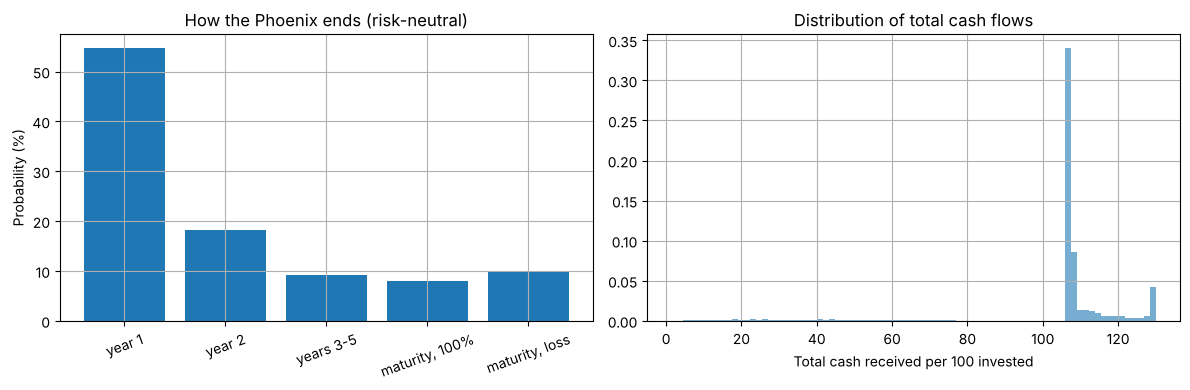

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(len(outcomes)), outcomes.values * 100)
ax[0].set_xticks(range(len(outcomes)), ["year 1", "year 2", "years 3-5", "maturity, 100%", "maturity, loss"], rotation=20)
ax[0].set_ylabel("Probability (%)"); ax[0].set_title("How the Phoenix ends (risk-neutral)")
ax[1].hist(total_cf * 100, bins=80, density=True, alpha=0.6)
ax[1].set_xlabel("Total cash received per 100 invested"); ax[1].set_title("Distribution of total cash flows")
plt.tight_layout(); plt.show()

**Lectura para la red.**

- Con la volatilidad local, el diseño que paga al menos un 6 % con la mayor protección baja las dos barreras: el
  cupón se cobra mientras el índice esté por encima de la barrera de cupón, y el capital solo se pierde si al
  final está por debajo de la barrera de capital.
- La memoria tiene valor para el inversor: sin ella, el cupón justo sube para compensar los cupones perdidos.
  Un nivel de amortización decreciente acorta la vida y reduce un poco el cupón. Amortizar desde el primer
  trimestre lo reduce bastante más: en los escenarios buenos el producto se cancela antes y el emisor se queda
  menos tiempo con la put que financia el cupón.
- La probabilidad de perder capital y la pérdida media deben ir en la documentación: son la otra cara del cupón.
- Para el emisor la estructura es corta digitales (los cupones y la amortización) y larga una put *down-and-in*
  muy fuera del dinero a cinco años: largo vega a largo plazo, largo dividendos y, en un worst-of, corto
  correlación. E4 agrega esos riesgos en un libro.

## 4. Comprobaciones

In [8]:
assert np.allclose(perf_lv[:, [3, -1]].mean(axis=0) * mkt.spot / np.array([mkt.forward(1.0), mkt.forward(5.0)]), 1.0, atol=0.01)
assert products.loc["barrier reverse convertible 1y (daily barrier 70%)", "local vol"] > products.loc["barrier reverse convertible 1y (daily barrier 70%)", "flat ATM vol"]
assert products.loc["Phoenix 5y (coupon barrier 70%, capital 60%)", "difference"] > 0
assert fund.iloc[:, 1].is_monotonic_increasing
assert (table.values[~np.isnan(table.values)] > 0).all()
assert best["fair coupon"] >= 0.06 and value_6 <= TARGET + 1e-9
assert abs(outcomes.sum() - 1) < 1e-12
assert var.loc["without memory", "fair coupon"] > var.loc["chosen design", "fair coupon"]
assert var.loc["autocall from the first quarter", "fair coupon"] < var.loc["chosen design", "fair coupon"]
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** ¿Qué participación ofrece la nota de capital protegido si se limita la subida al 50 % (*cap*)?
2. **Intermedio.** ¿Qué cupón justo tiene el Athena del diseño elegido? ¿Por qué es mayor que el del Phoenix?
3. **Avanzado.** La red cree que sus clientes aceptarían una barrera de capital del 60 % a cambio de más cupón. ¿Qué
   cupón paga el Phoenix con barrera de cupón 65 % y capital 60 %, y cuánto sube la probabilidad de pérdida frente
   al diseño elegido?

## Soluciones

In [9]:
print(f"participation without cap {cp_participation(perf_lv[:, -1]):.0%}; with a 50% cap {cp_participation(perf_lv[:, -1], cap=0.5):.0%}")

participation without cap 109%; with a 50% cap 119%


In [10]:
c_athena = phoenix_coupon(perf_lv, cb, kb, athena=True)
print(f"Athena {c_athena:.2%} vs Phoenix {best['fair coupon']:.2%}: the Athena only pays coupons when the index is")
print("above the initial level (on autocall or at maturity), so the investor gives up the coupons of the paths that")
print("stay between the barriers and is paid more per coupon in exchange.")

Athena 9.27% vs Phoenix 6.05%: the Athena only pays coupons when the index is
above the initial level (on autocall or at maturity), so the investor gives up the coupons of the paths that
stay between the barriers and is paid more per coupon in exchange.


In [11]:
c_alt = phoenix_coupon(perf_lv, 0.65, 0.60)
cf_alt, called_alt = autocall_cashflows(perf_lv, c_alt / 4, 0.65, 1.0, 0.60, True, False, 4)
loss_alt = ((called_alt < 0) & (perf_lv[:, -1] < 0.60)).mean()
print(f"coupon barrier 65%, capital 60%: fair coupon {c_alt:.2%}; probability of loss {loss_alt:.1%} vs {loss.mean():.1%}")

coupon barrier 65%, capital 60%: fair coupon 6.71%; probability of loss 12.1% vs 10.0%
